# 07 -- Full galaxy analysis, start to finish

**Goal:** this is the capstone notebook -- a complete, real analysis
combining every piece this notebook sequence has built and validated
separately:

1. An already-conditioned stellar template library (`04_template_calibration.ipynb`).
2. PA-aware dartboard spatial binning (`kinextract.binning`), matching
   a real, independently-verified reference binning scheme.
3. Per-spectrum sky-residual handling (residual-based variance inflation)
   and emission-line masking (`05_noise_correlation.ipynb`).
4. Correlated-noise-aware whitening (`05_noise_correlation.ipynb`).
5. Parallel per-bin fitting *and* parallel Laplace uncertainty -- both
   genuinely necessary at this scale, not a demonstration toggle.
6. Real moment maps and radial kinematic profiles, built the way IFU
   kinematics papers actually build them.

Read this notebook as *the reason each earlier notebook exists*: every step
below is doing something a previous notebook motivated and tested in
isolation. If any step here is unclear, that earlier notebook is where the
explanation lives -- this one focuses on how they fit together.

**Defaults to shipped, precomputed results (Section 0).** This is a
genuinely large computation (a 3GB cube download, then a ~30 minute
fit+Laplace-uncertainty run for 219 bins) -- not something a new user
should have to do just to see this notebook's own output. By default this
notebook loads `../data/muse/ngc5102_full_galaxy_results.npz` (built from
a real run of this exact pipeline, shipped with the package) and skips the
cube download, binning, fitting, and uncertainty steps entirely, going
straight to the plots. Set `FORCE_RECOMPUTE = True` in Section 0 to run
the real pipeline instead (needed if you change `RMAX_ARCSEC`/`PA_DEG`/any
fit setting below, or want to regenerate the shipped file itself).

**If you do run the real pipeline** (`FORCE_RECOMPUTE = True`): Per-bin
fitting is parallelized (`fit_losvd_robust_parallel`); uncertainty uses
`laplace_losvd_uncertainty_parallel` (this package's primary uncertainty
engine -- see `02_realistic_mock_fit.ipynb` for why it replaced bootstrap
as the default: substantially better h4 coverage at a fraction of
bootstrap's per-bin cost, since it needs one closed-form covariance per
regularization-strength candidate rather than `n_boot` full nonlinear
refits). **Results are also cached to disk** (Section 3) so a real run
only needs to happen once per configuration -- change `RMAX_ARCSEC` or
any other binning/fit choice and it recomputes automatically; leave
everything the same and it loads instantly from the cache instead.

**A note on memory**, if running the real pipeline. A real MUSE cube is
several GB on disk, several more once loaded (`load_muse_cube` converts to
float64); Section 4 frees the cube's own flux/error arrays explicitly
(`cube.flux = None`) as soon as every bin's own spectrum has been
extracted, since they're not needed again and the two parallel steps that
follow need their own headroom. `N_JOBS` (Section 3) is set explicitly
here for a specific laptop's measured core behavior -- the package's own
default (`n_jobs=None`, `multi_template.resolve_n_jobs`) is memory-aware
instead: it estimates available system memory and caps the worker count
only if needed, so the *same* notebook uses everything available on a
large-memory machine (an HPC node, say) without risking a crash on a
small one. Set `N_JOBS = None` (or your own explicit core count) if
you're running this somewhere with more memory to spare than this
notebook's own default assumes.

In [1]:
from __future__ import annotations
import dataclasses
import gc
import os
import pickle
import time
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from kinextract import (
    FitConfig, build_template_stack, compute_losvd_moments, mask_wavelength_windows,
    load_emiles_templates, load_muse_cube, combine_bin_spectrum_robust, white_light_image,
    laplace_losvd_uncertainty_parallel, detect_emission_lines, gauss_hermite_model,
    fit_losvd_robust_parallel, full_pixel_model,
    DartboardBins, build_reflected_sin_theta_edges, assign_spaxels_to_bins,
    pixel_aware_radial_edges, BACON2017_VARIANCE_CORRECTION_FACTOR, CAII_PROTECTED_WINDOWS,
)
from kinextract.multi_template import fit_losvd
from kinextract.template_reduction import load_template_subset
from kinextract.noise_model import whiten

CACHE_DIR = Path("cache")
CACHE_DIR.mkdir(exist_ok=True)

# Bacon et al. (2017)'s own recommended correction for the MUSE pipeline's per-spaxel
# STAT-extension variance being biased low relative to the true single-spaxel noise --
# see combine_bin_spectrum_robust's own docstring for the full derivation/citation.
MUSE_VARIANCE_CORRECTION_FACTOR = BACON2017_VARIANCE_CORRECTION_FACTOR


## 0. Shipped precomputed results (the default)

`RESULTS_PATH` below is checked out with the package -- if present (and
`FORCE_RECOMPUTE` is left `False`), every section below loads what it
needs from it directly instead of downloading the real cube or running
any fit. This is exactly the output a real `FORCE_RECOMPUTE=True` run of
this same notebook produces (see the very end of Section 4), so the plots
below are real results, not a synthetic stand-in.

In [2]:
RESULTS_PATH = Path("../data/muse/ngc5102_full_galaxy_results.npz")
FORCE_RECOMPUTE = False  # set False to load RESULTS_PATH instead of re-running the full pipeline

USE_SHIPPED_RESULTS = RESULTS_PATH.exists() and not FORCE_RECOMPUTE
if USE_SHIPPED_RESULTS:
    _shipped = np.load(RESULTS_PATH)
    print(f"using shipped precomputed results: {RESULTS_PATH} -- "
          f"cube download, binning, fitting, and Laplace uncertainty are all skipped below. "
          f"Set FORCE_RECOMPUTE=True above to run the real pipeline instead.")
else:
    print(f"{'FORCE_RECOMPUTE=True' if RESULTS_PATH.exists() else f'{RESULTS_PATH} not found'} -- "
          f"running the real pipeline below (cube download + full fit + Laplace uncertainty).")

using shipped precomputed results: ../data/muse/ngc5102_full_galaxy_results.npz -- cube download, binning, fitting, and Laplace uncertainty are all skipped below. Set FORCE_RECOMPUTE=True above to run the real pipeline instead.


In [3]:
from kinextract import plot_bin_map

## 1. Load the cube and the already-conditioned template library

A real E-MILES grid has hundreds of age/metallicity combinations -- far more
free parameters than any one spectrum's own S/N can usefully constrain, and
degenerate template mixtures are a real, measured source of bias (see
`02_realistic_mock_fit.ipynb`). `04_template_calibration.ipynb` solves this
once, for the whole target, by iteratively fitting every dartboard bin
against the full grid and keeping only the templates whose NNLS weight
actually survives somewhere -- `ngc5102_template_subset.npz`'s
`union_selected`. This notebook reuses that output directly rather than
re-deriving it: conditioning is a per-target, do-it-once step, not something
a downstream analysis notebook should redo on every run.

cube: 317x318 spaxels, pixel_scale=0.20000000000000015" (from shipped results, not loaded live)


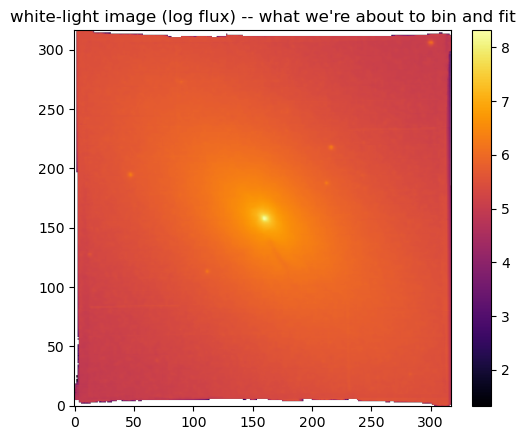

In [4]:
CUBE_PATH = "muse_download/ADP.2017-03-22T15:25:58.757.fits"
TEMPLATE_SUBSET_PATH = "../data/muse/ngc5102_template_subset.npz"
RADIAL_KINEMATICS_PATH = "../data/muse/ngc5102_radial_kinematics.npz"
EMILES_GRID = "../../src/kinextract/template_data/emiles_muse_grid.npz"
Z = 468.0 / 299792.458  # NGC 5102 systemic velocity ~468 km/s (NED)

if USE_SHIPPED_RESULTS:
    nx, ny = int(_shipped["nx"]), int(_shipped["ny"])
    pixel_scale = float(_shipped["pixel_scale"])
    white_light = _shipped["white_light"]
    print(f"cube: {ny}x{nx} spaxels, pixel_scale={pixel_scale}\" (from shipped results, not loaded live)")
else:
    if not os.path.exists(CUBE_PATH):
        raise FileNotFoundError(
            f"{CUBE_PATH} not found -- see 04_template_calibration.ipynb's DATA_MODE cell "
            "to download it (or point CUBE_PATH at any other MUSE Phase 3 cube)."
        )
    if not os.path.exists(RADIAL_KINEMATICS_PATH):
        raise FileNotFoundError(
            f"{RADIAL_KINEMATICS_PATH} not found -- run 04_template_calibration.ipynb's Section 7/10 "
            "in DATA_MODE='download' first (it now saves this radial (V, sigma) profile alongside the "
            "template subset -- see Section 4's own note on why this notebook needs it)."
        )

    cube = load_muse_cube(CUBE_PATH)
    ny, nx = cube.shape
    pixel_scale = cube.pixel_scale
    print(f"cube: {cube.flux.shape} (n_wave, ny, nx), pixel_scale={pixel_scale}\"")

    radial_kin = np.load(RADIAL_KINEMATICS_PATH)
    print(f"loaded radial (V, sigma) profile: {len(radial_kin['r_mid'])} radii "
          f"(from 04_template_calibration.ipynb's own full-grid fit)")

    subset = load_template_subset(TEMPLATE_SUBSET_PATH)
    union_idx = subset["union_selected"]
    select = list(zip(subset["template_ages"][union_idx].tolist(), subset["template_metals"][union_idx].tolist()))
    templates, template_wave, names, ages, metals = load_emiles_templates(EMILES_GRID, select=select)
    print(f"loaded {len(templates)} conditioned templates (of the full E-MILES grid):")
    for n, a, m in zip(names, ages, metals):
        print(f"  {n}  age={a:.2f} Gyr  [M/H]={m:+.2f}")

    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="All-NaN slice encountered", category=RuntimeWarning)
        white_light = white_light_image(cube)

fig, ax = plt.subplots(figsize=(5, 4.5))
with np.errstate(divide="ignore", invalid="ignore"):
    log_white_light = np.where(white_light > 0, np.log10(white_light), np.nan)
im = ax.imshow(log_white_light, origin="lower", cmap="inferno")
ax.set_title("white-light image (log flux) -- what we're about to bin and fit")
plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout(); plt.show()

## 2. PA-aware dartboard binning -- choose your own `RMAX_ARCSEC`

A single spaxel's own S/N falls off fast away from the nucleus -- too low,
on its own, to usefully constrain a LOSVD shape (`05_noise_correlation.ipynb`'s
own low-S/N aperture, for example, cannot support h3/h4 at all). Spatial
binning trades resolution for S/N by combining many faint spaxels into one
spectrum per bin.

**Why PA-aware, specifically.** `kinextract.binning`'s own default
(`uniform_theta_edges`) bins equal in angle, with no assumed axis -- the
right choice when nothing about the target's orientation is known yet.
Here we *do* know NGC 5102's kinematic major axis, so this notebook uses
`build_reflected_sin_theta_edges` + `assign_spaxels_to_bins`'s `pa_deg`
parameter instead: sectors come out narrowest along the major axis (where
rotation actually shows up in the LOSVD) and widest along the minor axis
(where it doesn't) -- concentrating angular resolution exactly where it's
useful.

**Radial edges: `pixel_aware_radial_edges`.** Builds `r_edges` directly
from this cube's own `pixel_scale`, so the collapsed center bin
(`DartboardBins`' `single_center_bin=True`, the default) contains *only*
the literal center pixel, and every subsequent ring grows geometrically
out to `RMAX_ARCSEC` -- structurally impossible for an inner ring to end
up narrower than a pixel (which would leave it permanently empty, since
no real spaxel could ever populate it).

**`RMAX_ARCSEC` is the one parameter you're meant to change.** Larger
values cover more of the field at the cost of more bins (and therefore
more per-bin fitting/uncertainty wall-clock, the dominant cost -- see the
intro markdown above). The default (30\") is a real science radius on
this target, not a coarsened demo -- change it here, then re-run from
this cell down; a different value invalidates the cache automatically
(Section 3). `N_RADIAL_BINS` controls how finely that range is divided
(geometrically) -- also part of the cache key.

275 populated bins (17 radial x 20 angular) -- binning geometry from shipped results, not recomputed


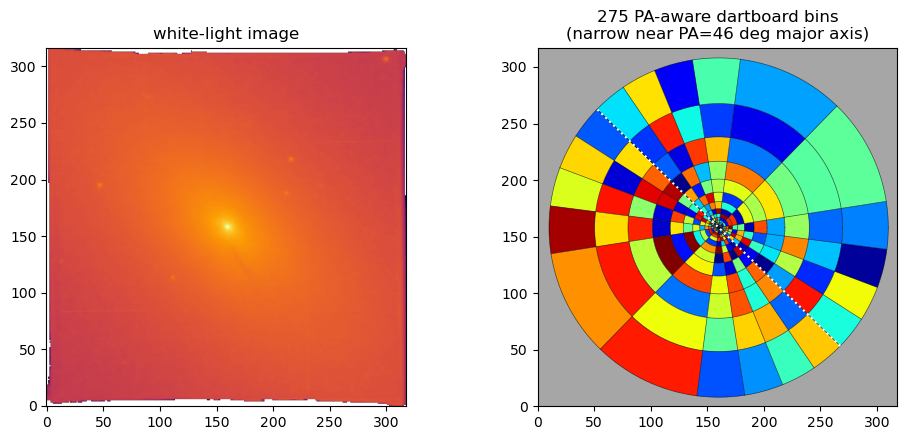

In [5]:
PA_DEG = 45.77 + 90.0       # NGC 5102's own kinematic major-axis PA
N_THETA_PER_QUADRANT = 5    # matches an independent reference bin_v.out exactly
RMAX_ARCSEC = 30.0           # <-- the parameter to change; radial coverage in arcsec -- ignored when USE_SHIPPED_RESULTS
N_RADIAL_BINS = 17           # matches the old reference pattern's own bin count -- geometric from 1 pixel to RMAX_ARCSEC

if USE_SHIPPED_RESULTS:
    r_edges = _shipped["r_edges"]
    theta_edges = _shipped["theta_edges"]
    bx, by = (float(v) for v in _shipped["center"])
    bins = DartboardBins(r_edges=r_edges, theta_edges=theta_edges, center=(bx, by))
    bin_ids = _shipped["bin_ids"].tolist()
    n_bins = len(bin_ids)
    _r_index, _theta_index = _shipped["r_index"], _shipped["theta_index"]
    _r_mid, _theta_mid, _n_spaxels = _shipped["r_mid"], _shipped["theta_mid"], _shipped["n_spaxels"]
    bin_table = [
        dict(bin_id=int(bid), r_index=int(_r_index[i]),
             theta_index=(None if _theta_index[i] < 0 else int(_theta_index[i])),
             r_mid=float(_r_mid[i]), theta_mid=(None if np.isnan(_theta_mid[i]) else float(_theta_mid[i])),
             n_spaxels=int(_n_spaxels[i]))
        for i, bid in enumerate(bin_ids)
    ]
    print(f"{n_bins} populated bins ({bins.n_radial} radial x {bins.n_angular} angular) -- "
          f"binning geometry from shipped results, not recomputed")
else:
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="All-NaN slice encountered", category=RuntimeWarning)
        signal_map = np.nanmedian(cube.flux, axis=0)
        noise_map = np.nanmedian(cube.error, axis=0)
    good0 = np.isfinite(signal_map) & np.isfinite(noise_map) & (signal_map > 0) & (noise_map > 0)

    by, bx = np.unravel_index(np.nanargmax(np.where(good0, signal_map, np.nan)), signal_map.shape)
    x_arcsec = (np.arange(nx) - bx) * pixel_scale
    y_arcsec = (np.arange(ny) - by) * pixel_scale
    xx, yy = np.meshgrid(x_arcsec, y_arcsec)
    r_arcsec = np.hypot(xx, yy)
    good = good0 & (r_arcsec <= RMAX_ARCSEC)

    r_edges = pixel_aware_radial_edges(pixel_scale, RMAX_ARCSEC, N_RADIAL_BINS)
    theta_edges = build_reflected_sin_theta_edges(N_THETA_PER_QUADRANT)
    bins = DartboardBins(r_edges=r_edges, theta_edges=theta_edges, center=(bx, by))
    bin_id_map, bin_table = assign_spaxels_to_bins((ny, nx), bins, pixel_scale=pixel_scale, pa_deg=PA_DEG)
    bin_id_map[~good] = -1
    bin_table = [row for row in bin_table if np.any(bin_id_map == row["bin_id"])]
    bin_ids = [row["bin_id"] for row in bin_table]
    n_bins = len(bin_table)

    print(f"{n_bins} populated bins ({bins.n_radial} radial x {bins.n_angular} angular) "
          f"out to r={r_edges[-1]:.2f}\" (RMAX_ARCSEC={RMAX_ARCSEC:.2f}\")")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
with np.errstate(divide="ignore", invalid="ignore"):
    log_white_light = np.where(white_light > 0, np.log10(white_light), np.nan)
axes[0].imshow(log_white_light, origin="lower", cmap="inferno")
axes[0].set_title("white-light image")
# random (not spatially-ordered) color per bin -- tab20 cycles through only 20
# colors, so with 239 bins many *adjacent* wedges land on the same or a
# similar swatch; a random permutation over a wide-gamut colormap instead
# makes neighboring bins land on unrelated colors almost always, which is
# the property that actually matters for "can I tell bins apart"
_bin_color_rng = np.random.default_rng(0)
_random_bin_value = {bid: v for bid, v in zip(bin_ids, _bin_color_rng.permutation(len(bin_ids)))}
plot_bin_map(axes[1], bin_table, bins, _random_bin_value, center_pix=bins.center,
             pa_deg=PA_DEG, pixel_scale=pixel_scale, background=white_light,
             cmap="jet", vmin=0, vmax=len(bin_ids) - 1, add_cbar=False)
axes[1].set_xlim(0, nx); axes[1].set_ylim(0, ny)
axes[1].set_title(f"{n_bins} PA-aware dartboard bins\n(narrow near PA={PA_DEG-90:.0f} deg major axis)")
plt.tight_layout(); plt.show()

## 3. Caching -- this run only needs to happen once per configuration

Everything below (masking, fitting, Laplace uncertainty) is deterministic
given the binning geometry, template selection, `rho`, and uncertainty
settings -- so this cell fingerprints all of that into one `CACHE_TAG`
and, if a matching result already exists on disk, loads it instantly
instead of recomputing. Change `RMAX_ARCSEC` (or any other setting in
Section 2, or `MEASURED_RHO`/`N_SAMPLES` below) and the tag changes, so a
new configuration always recomputes rather than silently reusing a stale
result for a different question.

In [6]:
# MEASURED_RHO is a fallback only -- fit_losvd_robust's measure_rho=True (below) measures
# each bin's own pixel correlation directly instead of trusting one global value (a single
# rho does not transfer across this target's own real S/N range -- see dev_notes/
# uncertainty/FINDINGS.md).
MEASURED_RHO = 0.88  # from 05_noise_correlation.ipynb -- unused once measure_rho=True kicks in
N_SAMPLES = 300  # laplace_losvd_uncertainty's own default posterior-predictive sample budget
LAPLACE_SEED = 0
N_JOBS = 4  # measured faster than n_jobs=None (os.cpu_count()) on this machine's
            # performance/efficiency core mix -- see fit_losvd_parallel's own docstring.
            # An explicit value like this always overrides the package's own memory-aware
            # default (multi_template.resolve_n_jobs) -- on a large-memory machine (e.g. an
            # HPC node), set N_JOBS = None (or your own core count) instead, to use everything
            # available rather than this laptop-specific choice.
SMOOTH_WINDOW_A = 3.0  # this target's ~1.25A/pix spacing needs a narrower window than the
                       # package's own 8.0A default -- see dev_notes/real_data_sigma/FINDINGS.md.
INFLATION_CAP = 8.0    # fit_losvd_robust's max per-pixel error inflation factor
# Skip the inflate-and-refit step only when NOTHING anywhere needs inflating -- gated on
# the local inflation profile's own max, not a global chi2/dof average, since a bin can
# look fine on average while still having a real localized contaminated window -- see
# dev_notes/real_data_sigma/FINDINGS.md.
MIN_INFLATION_TO_APPLY = 1.1

# Continuum-cofitting -- OFF for this target (unlike N4751, which needs it -- see
# n4751_full_galaxy_analysis.ipynb). Fixed lam=4096/penalty_order=3, the same validated
# combination used everywhere else in this package -- see dev_notes/continuum/FINDINGS.md.
CONTINUUM_KNOTS = None
LOSVD_LAM = 4096.0
LOSVD_PENALTY_ORDER = 3
LAM_C = 2.0     # inert here -- only takes effect when CONTINUUM_KNOTS is not None
RIDGE_C = 0.1   # inert here -- only takes effect when CONTINUUM_KNOTS is not None

CACHE_TAG = (f"rmax{RMAX_ARCSEC:.1f}_pa{PA_DEG:.1f}_nt{N_THETA_PER_QUADRANT}_nr{N_RADIAL_BINS}_nb{n_bins}_measrho_mininfl{MIN_INFLATION_TO_APPLY:.1f}"
             f"_laplace_nsamp{N_SAMPLES}_seed{LAPLACE_SEED}_smooth{SMOOTH_WINDOW_A:.1f}_cap{INFLATION_CAP:.1f}"
             f"_continuum{CONTINUUM_KNOTS}_lamc{LAM_C:.1f}_lam{LOSVD_LAM:.0f}_order{LOSVD_PENALTY_ORDER}_caii")
CACHE_PATH = CACHE_DIR / f"full_galaxy_{CACHE_TAG}.pkl"
print(f"cache key: {CACHE_TAG}")
print(f"cache path: {CACHE_PATH}  (exists: {CACHE_PATH.exists()})")


cache key: rmax30.0_pa135.8_nt5_nr17_nb275_measrho_mininfl1.1_laplace_nsamp300_seed0_smooth3.0_cap8.0_continuumNone_lamc2.0_lam4096_order3_caii
cache path: cache/full_galaxy_rmax30.0_pa135.8_nt5_nr17_nb275_measrho_mininfl1.1_laplace_nsamp300_seed0_smooth3.0_cap8.0_continuumNone_lamc2.0_lam4096_order3_caii.pkl  (exists: True)


## 4. Per-bin masking, fitting, and Laplace uncertainty

Three things happen per bin:

- **Emission-line masking** (`cleaning.detect_emission_lines`): whether a
  candidate emission line is actually present depends on the spectrum, so
  it's re-checked per bin rather than masked unconditionally. Sky-residual
  handling is not a wavelength mask at all -- it's the per-spectrum method
  below, since a fixed window list applied identically to every spectrum
  can't track how contamination severity actually varies bin to bin.
- **Per-spectrum, residual-based variance inflation, the default defense
  against unmodeled contamination** (`fit_losvd_robust_parallel`). Real
  chi2_red on this target runs 11-28 (`05_noise_correlation.ipynb`) -- the
  input noise vector is structurally under-scaled at many wavelengths,
  not just at a handful of genuinely bad pixels, which is exactly the
  regime where a hard sigma-clip alone can compound a model bias rather
  than fix contamination. `fit_losvd_robust` instead: fits once with a
  loose, cleanup-only clip; takes the whitened residual at every pixel;
  builds a median-filtered local scale of `|residual|` in wavelength
  (smooths past single-pixel shot noise while preserving a real
  sky-residual feature's own width); turns that into a per-pixel error
  inflation factor (floored at 1, capped at `INFLATION_CAP` so a
  badly-contaminated window is downweighted, not zeroed out); and refits
  against the inflated errors. A second loose clip on top of that final
  fit is cleanup only, not the primary defense (`kinextract.robust_fit`'s
  own module docstring has the full algorithm and real-data validation
  record).

  **This still needs real per-target tuning, not a fire-and-forget
  default** -- `SMOOTH_WINDOW_A`/`INFLATION_CAP` above are a starting
  point, not a validated universal choice.
- **Grid centering from a cached radial profile, then fitting in
  parallel** (`fit_losvd_robust_parallel`): each bin's velocity grid is
  centered at `V +- 7*sigma` using its own radius's cached `(V, sigma)`
  from `04_template_calibration.ipynb`'s own full-grid fit (Section 1),
  not an independent per-bin wide-pass fit. Checked directly against a
  real run of this notebook: at fixed radius, `V` varies by at most
  ~30 km/s across angle and `sigma` by ~5-16 km/s -- both tiny next to
  the `7*sigma` margin (175-340 km/s here), so a per-radius estimate
  safely brackets every individual bin's own true `V`/`sigma`, at a small
  fraction of an independent per-bin wide-pass fit's own cost. Once
  centered, the real fit -- `FitConfig`'s actual choices (regularization,
  `rho`, ...) and variance inflation -- runs across *all* bins at once,
  parallelized the same way `fit_losvd_parallel` is.
- **Laplace uncertainty, in parallel** (`laplace_losvd_uncertainty_parallel`,
  this package's primary uncertainty engine -- see
  `02_realistic_mock_fit.ipynb` for the coverage-sweep evidence behind
  that default), on the *same* whitened design matrix and pixel set each
  bin's own point estimate actually converged on -- built from that bin's
  own `errors_inflated` (not the original `errors`) and with the final
  cleanup-clip's own `clipped_mask` applied, so the Laplace covariance is
  evaluated at the exact inputs the point estimate itself used. Continuum-
  cofitting is not used in this notebook, so `laplace_losvd_uncertainty`'s
  own "no continuum support yet" scope limit (see its module docstring)
  doesn't apply here.

**A note on warnings.** `select_lambda_aic_local` (inside every fit and
Laplace covariance evaluation below) checks every candidate `lam` in its
own scan grid, not just the one finally selected -- for some bins, a
rejected high-`lam` candidate trips `FitConfig`'s "knot spacing much finer
than `knot_spacing_kms` is calibrated against" warning even though that
candidate never gets used. Real diagnostic, over-eager trigger (fires
per-candidate, not per-selection) -- deduplicated to at most once per
worker process rather than raw hundreds of prints (see
`multi_template._limit_worker_threads`'s own docstring).

In [7]:
if USE_SHIPPED_RESULTS:
    bin_data = {}
    for i, bid in enumerate(bin_ids):
        bin_data[bid] = dict(
            r_mid=float(_shipped["r_mid"][i]),
            theta_mid=(None if np.isnan(_shipped["theta_mid"][i]) else float(_shipped["theta_mid"][i])),
            n_spaxels=int(_shipped["n_spaxels"][i]),
            moments=dict(vherm=float(_shipped["vherm"][i]), sherm=float(_shipped["sherm"][i]),
                         h3=float(_shipped["h3"][i]), h4=float(_shipped["h4"][i])),
            vherm_std=float(_shipped["vherm_std"][i]), sherm_std=float(_shipped["sherm_std"][i]),
            h3_std=float(_shipped["h3_std"][i]), h4_std=float(_shipped["h4_std"][i]),
            n_clipped=int(_shipped["n_clipped"][i]),
            errors=np.empty(int(_shipped["n_pix"][i])),  # only ever consumed via len(...) downstream
        )
    example_ids = _shipped["example_ids"].tolist()
    for i, bid in enumerate(example_ids):
        bd = bin_data[bid]
        for key in ("wave_fit", "flux_fit", "model", "clipped_mask", "v_grid", "b_median", "b_p16", "b_p84",
                    "errors_inflated", "inflation_factor"):
            bd[key] = _shipped[f"example_{i}_{key}"]
    print(f"loaded {len(bin_data)} bins' worth of moments/uncertainty from shipped results "
          f"({len(example_ids)} with full per-pixel spectra/LOSVD, for Section 5's own example-bin plots) "
          f"-- fit + Laplace uncertainty skipped entirely")
else:
    WAVEFITMIN, WAVEFITMAX = 8400.0, 8800.0
    NSIG = 7
    # deduplicated, not silenced -- see Section 4's own note on why this fires
    # per rejected lam-candidate, not per bin
    warnings.filterwarnings("once", message=r".*much finer than.*knot_spacing_kms.*")

    # jupyter nbconvert --execute does not stream a cell's own print() output live --
    # also append the same progress lines to a plain log file, flushed immediately, so
    # an outside `tail -f` can watch a long real run without waiting on it blind.
    _progress_log_path = CACHE_DIR / "full_galaxy_progress.log"
    _progress_log = open(_progress_log_path, "a")
    def _log(msg):
        print(msg)
        _progress_log.write(msg + "\n")
        _progress_log.flush()

    t_start = time.time()
    _log(f"=== run started {time.strftime('%Y-%m-%d %H:%M:%S')}, {n_bins} bins ===")
    bin_data = {}
    A_stack_list, flux_fit_list, errors_list, wave_fit_list, cfg_list = [], [], [], [], []

    _log(f"preparing {n_bins} bins (serial, cheap -- grid centers come from the cached "
         f"radial profile, not a per-bin wide-pass fit)...")
    for _prep_i, row in enumerate(bin_table):
        bin_id = row["bin_id"]
        spaxel_mask = bin_id_map == bin_id
        wave_obs, flux_obs, error_obs = combine_bin_spectrum_robust(
            cube, spaxel_mask, variance_correction_factor=MUSE_VARIANCE_CORRECTION_FACTOR)
        wave_rest = wave_obs / (1.0 + Z)
        in_window = (wave_rest >= WAVEFITMIN) & (wave_rest <= WAVEFITMAX)
        wave_w, flux_w, error_w = wave_rest[in_window], flux_obs[in_window], error_obs[in_window]

        emission_windows = detect_emission_lines(wave_w, flux_w, error_w)
        wave_fit, flux_fit = mask_wavelength_windows(wave_w, flux_w, windows=emission_windows)
        _, errors = mask_wavelength_windows(wave_w, error_w, windows=emission_windows)

        # nearest-radius lookup against 04_template_calibration.ipynb's own cached (V, sigma)
        # profile -- see Section 4's own note for why this is a safe stand-in for an
        # independent per-bin wide-pass fit here.
        r_idx = int(np.argmin(np.abs(radial_kin["r_mid"] - row["r_mid"])))
        v0, sigma0 = float(radial_kin["vherm"][r_idx]), float(radial_kin["sherm"][r_idx])

        # Fixed lam (see Section 3 above) -- same combination for point estimate and
        # uncertainty, no per-bin lam re-selection needed downstream.
        cfg = FitConfig(vmin=v0 - NSIG * sigma0, vmax=v0 + NSIG * sigma0, rho=MEASURED_RHO,
                         continuum_knots=CONTINUUM_KNOTS, lam_c=LAM_C, ridge_c=RIDGE_C,
                         lam_selection="fixed", lam=LOSVD_LAM, penalty_order=LOSVD_PENALTY_ORDER)
        v_grid = cfg.build_velocity_grid()
        A_stack = build_template_stack(wave_fit, template_wave, templates, v_grid)

        A_stack_list.append(A_stack); flux_fit_list.append(flux_fit); errors_list.append(errors)
        wave_fit_list.append(wave_fit); cfg_list.append(cfg)
        bin_data[bin_id] = dict(wave_fit=wave_fit, flux_fit=flux_fit, errors=errors,
                                 n_spaxels=int(spaxel_mask.sum()),
                                 n_emission_windows=len(emission_windows),
                                 v_grid=v_grid,
                                 r_mid=row["r_mid"], theta_mid=row["theta_mid"])
        if (_prep_i + 1) % 20 == 0:
            _el = time.time() - t_start
            _log(f"    ...{_prep_i + 1}/{n_bins} bins extracted ({_el:.0f}s elapsed, "
                 f"{_el / (_prep_i + 1):.2f}s/bin so far)")
    t_wide = time.time() - t_start
    n_with_emission = sum(1 for b in bin_data.values() if b["n_emission_windows"] > 0)
    _log(f"  done in {t_wide:.0f}s ({n_with_emission} bins with detected emission)")

    # cube.flux/cube.error (a real MUSE cube is several GB as float64) are not needed
    # again -- every bin's own spectrum is already captured in bin_data/A_stack_list.
    # Free them explicitly *before* the two parallel steps below, which each need their
    # own headroom (n_jobs worker processes, each holding a per-bin design matrix) --
    # see this notebook's intro markdown and multi_template.resolve_n_jobs's own
    # docstring for the memory-safety reasoning (this is what let a real 16GB machine
    # run this notebook without exhausting memory).
    cube.flux = None
    cube.error = None
    gc.collect()

    # Both parallel steps below run in batches, not one single call over all n_bins at
    # once -- ProcessPoolExecutor.map (what fit_losvd_robust_parallel/laplace_losvd_
    # uncertainty_parallel use internally) blocks until *every* future in the batch
    # completes before returning anything, so a single call over all bins gives zero
    # visibility into progress until the entire run finishes.
    BATCH_SIZE = 20

    _log(f"fitting {n_bins} bins in parallel with variance inflation (n_jobs={N_JOBS}, "
         f"smooth_window_A={SMOOTH_WINDOW_A}, inflation_cap={INFLATION_CAP}), "
         f"in batches of {BATCH_SIZE}...")
    t0 = time.time()
    results = []
    for _b_start in range(0, n_bins, BATCH_SIZE):
        _b_end = min(_b_start + BATCH_SIZE, n_bins)
        _t_batch = time.time()
        _batch_results = fit_losvd_robust_parallel(
            A_stack_list[_b_start:_b_end], flux_fit_list[_b_start:_b_end],
            errors_list[_b_start:_b_end], cfg_list[_b_start:_b_end],
            wave_fit_list=wave_fit_list[_b_start:_b_end], n_jobs=N_JOBS,
            smooth_window_A=SMOOTH_WINDOW_A, inflation_cap=INFLATION_CAP, cleaning_method="inflate",
            excluded_wavelength_windows=CAII_PROTECTED_WINDOWS,
            measure_rho=True, min_inflation_to_apply=MIN_INFLATION_TO_APPLY)
        results.extend(_batch_results)
        _dt_batch = time.time() - _t_batch
        _el = time.time() - t0
        _log(f"    ...bins {_b_start}-{_b_end - 1}/{n_bins} done in {_dt_batch:.0f}s "
             f"({_dt_batch / (_b_end - _b_start):.1f}s/bin this batch), {_el:.0f}s elapsed total")
    t_fit = time.time() - t0
    _log(f"  done in {t_fit:.0f}s ({t_fit/n_bins:.1f}s/bin)")

    # Each bin's own point-estimate fit used its own measured rho (fit_losvd_robust's
    # measure_rho=True, Section 3/4 above), not the placeholder MEASURED_RHO every cfg in
    # cfg_list was built with -- reproducing that fit downstream (for plotting, for Laplace
    # uncertainty) needs the same rho, from each result's own rho_used, not cfg_list as-is.
    cfg_list_measured = [dataclasses.replace(cfg, rho=result["rho_used"])
                          for cfg, result in zip(cfg_list, results)]

    A_stack_w_list, y_w_list = [], []  # rebuilt against each bin's own inflated errors, for Laplace below
    for bin_id, result, A_stack, flux_fit, wave_fit, cfg in zip(
            bin_ids, results, A_stack_list, flux_fit_list, wave_fit_list, cfg_list_measured):
        bd = bin_data[bin_id]
        bd["result"] = result
        bd["moments"] = compute_losvd_moments(bd["v_grid"], result["b"], fit_h3h4=True)
        bd["clipped_mask"] = result["clipped_mask"]
        bd["n_clipped"] = result["n_clipped"]

        # the point estimate's own final fit ran against this bin's *inflated* errors,
        # not the original ones -- rebuild the whitened design matrix that way, so both
        # the plotted model (below) and the Laplace covariance (further down) are
        # evaluated at the exact inputs the point estimate itself used.
        errors_inflated = result["errors_inflated"]
        bd["errors_inflated"] = errors_inflated
        bd["inflation_factor"] = result["inflation_factor"]
        A_stack_w, y_w, L = whiten(A_stack, flux_fit, errors_inflated, rho=cfg.rho)
        A_stack_w_list.append(A_stack_w); y_w_list.append(y_w)
        bd["L"] = L
        # full-pixel model for plotting -- w/b are global, so apply them to every
        # pixel (including clipped ones), not just the surviving subset, so later
        # sections can show the whole spectrum with clipped points marked
        bd["model"] = L @ full_pixel_model(result, A_stack_w, wave_fit, cfg)

    n_clipped_total = sum(bd["n_clipped"] for bd in bin_data.values())
    n_pix_total = sum(len(bd["errors"]) for bd in bin_data.values())
    per_bin_frac = [bd["n_clipped"] / len(bd["errors"]) for bd in bin_data.values()]
    _log(f"  final cleanup clip removed {n_clipped_total}/{n_pix_total} pixels overall "
         f"({100*n_clipped_total/n_pix_total:.1f}%), median {np.median(per_bin_frac):.1%} per bin, "
         f"max {np.max(per_bin_frac):.1%} per bin -- variance inflation is the primary defense, "
         f"this is cleanup on top of it")

    _log(f"computing Laplace uncertainty for {n_bins} bins in parallel "
         f"(n_jobs={N_JOBS}, n_samples={N_SAMPLES}), in batches of {BATCH_SIZE}...")
    t0 = time.time()
    # Laplace covariance on each bin's own *cleaned* pixel set (matching what its
    # point estimate actually converged on), not the original full one -- keeps the
    # Hessian evaluated at the same design matrix the point estimate itself used.
    A_stack_w_clean_list = [A_stack_w_list[i][:, ~bin_data[bid]["clipped_mask"], :]
                             for i, bid in enumerate(bin_ids)]
    y_w_clean_list = [y_w_list[i][~bin_data[bid]["clipped_mask"]] for i, bid in enumerate(bin_ids)]
    wave_fit_list_clean = [wave_fit_list[i][~bin_data[bid]["clipped_mask"]] for i, bid in enumerate(bin_ids)]
    laps = []
    for _b_start in range(0, n_bins, BATCH_SIZE):
        _b_end = min(_b_start + BATCH_SIZE, n_bins)
        _t_batch = time.time()
        _batch_laps = laplace_losvd_uncertainty_parallel(
            A_stack_w_clean_list[_b_start:_b_end], y_w_clean_list[_b_start:_b_end],
            cfg_list_measured[_b_start:_b_end], n_samples=N_SAMPLES, seed=LAPLACE_SEED, n_jobs=N_JOBS,
            wave_fit=wave_fit_list_clean[_b_start:_b_end], n_continuum_knots=CONTINUUM_KNOTS,
            lam_c=LAM_C, ridge_c=RIDGE_C)
        laps.extend(_batch_laps)
        _dt_batch = time.time() - _t_batch
        _el = time.time() - t0
        _log(f"    ...bins {_b_start}-{_b_end - 1}/{n_bins} done in {_dt_batch:.0f}s "
             f"({_dt_batch / (_b_end - _b_start):.1f}s/bin this batch), {_el:.0f}s elapsed total")
    t_lap = time.time() - t0
    _log(f"  done in {t_lap:.0f}s ({t_lap/n_bins:.1f}s/bin)")

    for bin_id, lap in zip(bin_ids, laps):
        bd = bin_data[bin_id]
        bd["sherm_std"] = lap["sherm_std"]
        bd["vherm_std"] = lap["vherm_std"]
        bd["h3_std"] = lap["h3_std"]
        bd["h4_std"] = lap["h4_std"]
        # The reported LOSVD is the Laplace posterior-predictive median/band, not the
        # point estimate -- the band is centered on b_median, not on bd["result"]["b"],
        # so presenting the point estimate next to a band that isn't centered on it is
        # misleading (see uncertainty.bootstrap_losvd's own b_median docstring for the
        # same reasoning, which applies identically here).
        bd["b_median"] = lap["b_median"]
        bd["b_p16"] = lap["b_p16"]
        bd["b_p84"] = lap["b_p84"]

    t_total = time.time() - t_start
    _log(f"total: {t_total/60:.1f} min for {n_bins} bins")

    with open(CACHE_PATH, "wb") as f:
        pickle.dump(bin_data, f)
    _log(f"cached to {CACHE_PATH}")

    # Also refresh the small, shippable results file Section 0 defaults to loading --
    # a real FORCE_RECOMPUTE=True run should keep that file in sync with the latest
    # pipeline/method, not leave it stale after a code change like this one.
    example_ids = sorted(bin_ids)[:: max(1, len(bin_ids) // 4)][:4]
    _save_kwargs = dict(
        nx=nx, ny=ny, pixel_scale=pixel_scale, pa_deg=PA_DEG, white_light=white_light,
        r_edges=r_edges, theta_edges=theta_edges, center=np.array([bx, by]),
        bin_ids=np.array(bin_ids),
        r_mid=np.array([row["r_mid"] for row in bin_table]),
        theta_mid=np.array([np.nan if row["theta_mid"] is None else row["theta_mid"] for row in bin_table]),
        r_index=np.array([row["r_index"] for row in bin_table]),
        theta_index=np.array([-1 if row["theta_index"] is None else row["theta_index"] for row in bin_table]),
        n_spaxels=np.array([row["n_spaxels"] for row in bin_table]),
        vherm=np.array([bin_data[b]["moments"]["vherm"] for b in bin_ids]),
        sherm=np.array([bin_data[b]["moments"]["sherm"] for b in bin_ids]),
        h3=np.array([bin_data[b]["moments"]["h3"] for b in bin_ids]),
        h4=np.array([bin_data[b]["moments"]["h4"] for b in bin_ids]),
        vherm_std=np.array([bin_data[b]["vherm_std"] for b in bin_ids]),
        sherm_std=np.array([bin_data[b]["sherm_std"] for b in bin_ids]),
        h3_std=np.array([bin_data[b]["h3_std"] for b in bin_ids]),
        h4_std=np.array([bin_data[b]["h4_std"] for b in bin_ids]),
        n_clipped=np.array([bin_data[b]["n_clipped"] for b in bin_ids]),
        n_pix=np.array([len(bin_data[b]["errors"]) for b in bin_ids]),
        example_ids=np.array(example_ids),
    )
    for i, bid in enumerate(example_ids):
        bd = bin_data[bid]
        for key in ("wave_fit", "flux_fit", "model", "clipped_mask", "v_grid", "b_median", "b_p16", "b_p84",
                    "errors_inflated", "inflation_factor"):
            _save_kwargs[f"example_{i}_{key}"] = bd[key]
    np.savez_compressed(RESULTS_PATH, **_save_kwargs)
    _log(f"refreshed shipped results file: {RESULTS_PATH} ({RESULTS_PATH.stat().st_size/1e6:.2f} MB)")
    _progress_log.close()

loaded 275 bins' worth of moments/uncertainty from shipped results (4 with full per-pixel spectra/LOSVD, for Section 5's own example-bin plots) -- fit + Laplace uncertainty skipped entirely


## 5. A few example bins, before trusting the aggregate

Same discipline this project's own head-to-head pPXF comparison uses:
look at individual spectral fits and their extracted LOSVDs directly,
not just the summary numbers, before trusting a map or profile built from
all of them.

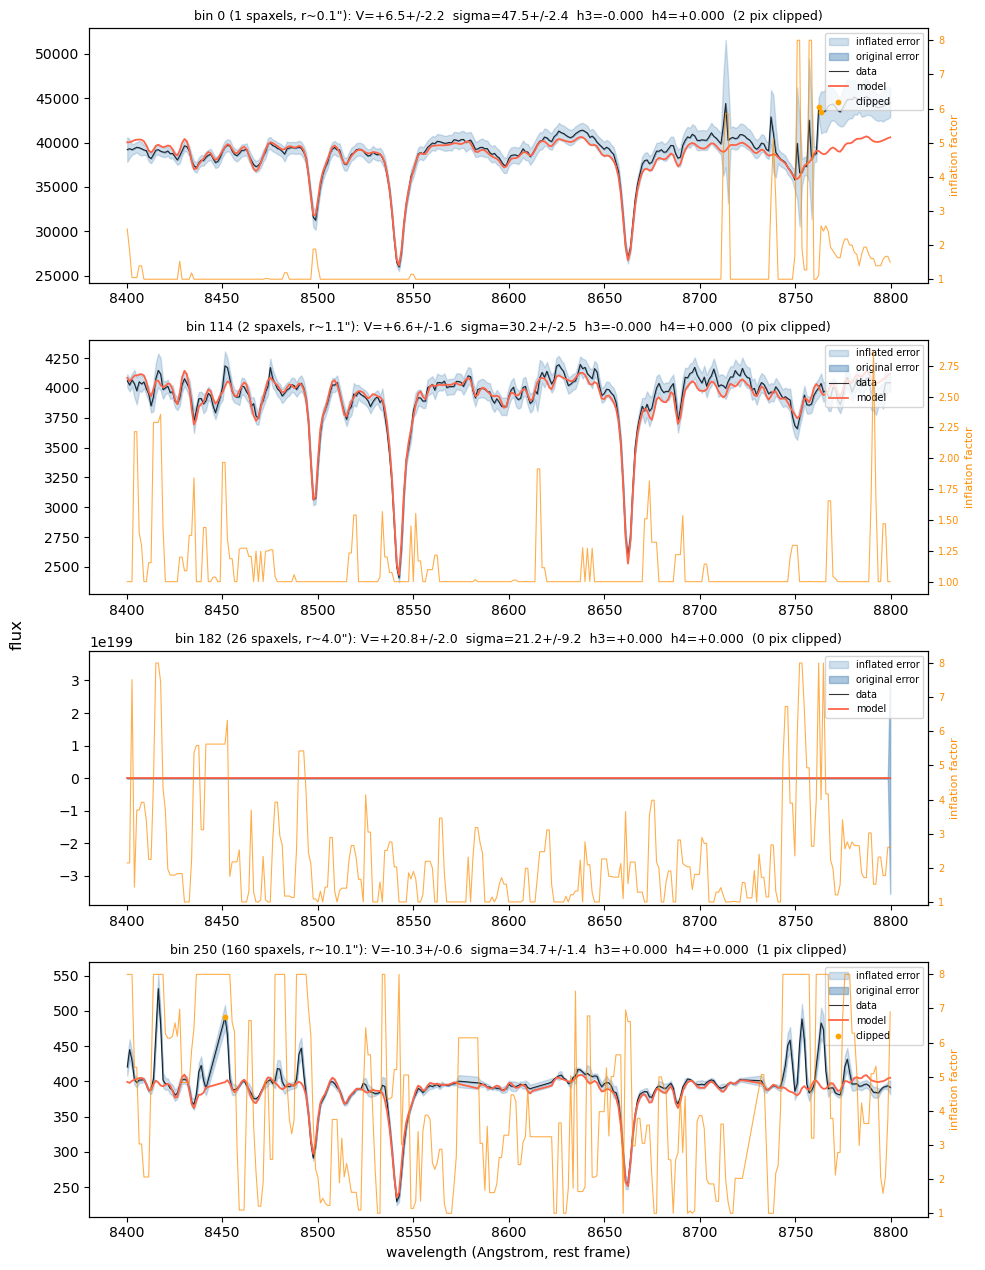

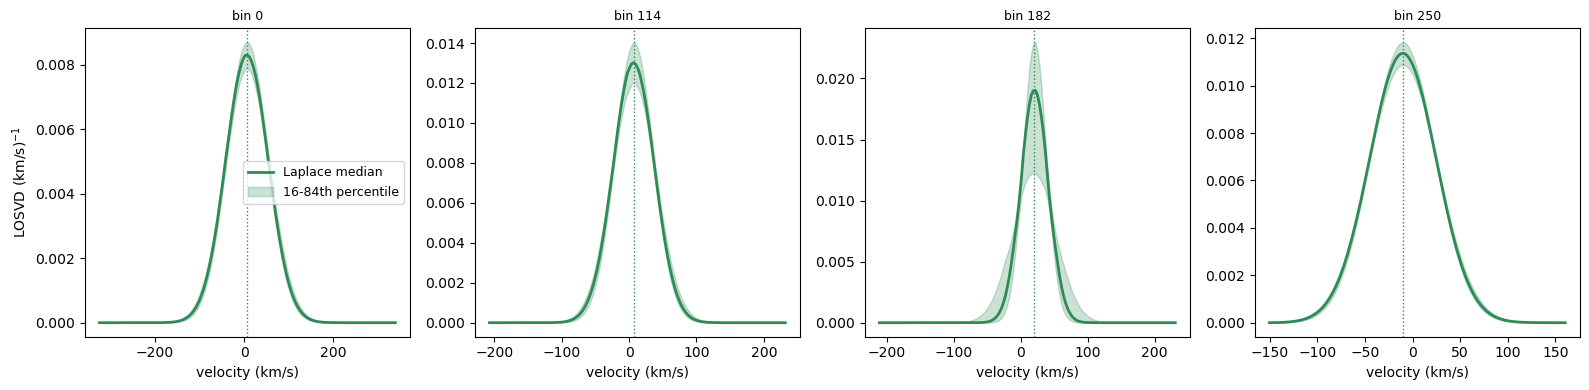

In [8]:
example_ids = sorted(bin_ids)[:: max(1, len(bin_ids) // 4)][:4]

fig, axes = plt.subplots(len(example_ids), 1, figsize=(10, 3.2 * len(example_ids)), sharex=False)
axes = np.atleast_1d(axes)
for ax, bid in zip(axes, example_ids):
    bd = bin_data[bid]
    errors_inflated = bd["errors_inflated"]
    # Inflated-error band first (wider, lighter) so the ORIGINAL error band drawn on
    # top of it visually reveals how much a wavelength's own error grew -- the gap
    # between the two bands *is* the inflation, not a separate readout you have to
    # cross-reference against a second axis.
    ax.fill_between(bd["wave_fit"], bd["flux_fit"] - errors_inflated, bd["flux_fit"] + errors_inflated,
                     color="steelblue", alpha=0.25, zorder=0, label="inflated error")
    ax.fill_between(bd["wave_fit"], bd["flux_fit"] - bd["errors"], bd["flux_fit"] + bd["errors"],
                     color="steelblue", alpha=0.45, zorder=1, label="original error")
    ax.plot(bd["wave_fit"], bd["flux_fit"], color="black", lw=0.8, alpha=0.8, label="data", zorder=2)
    ax.plot(bd["wave_fit"], bd["model"], color="tomato", lw=1.3, label="model", zorder=3)
    clipped = bd["clipped_mask"]
    if np.any(clipped):
        ax.scatter(bd["wave_fit"][clipped], bd["flux_fit"][clipped], color="orange", s=10,
                   zorder=5, label="clipped")
    m = bd["moments"]
    ax.set_title(f"bin {bid} ({bd['n_spaxels']} spaxels, r~{bd['r_mid']:.1f}\"): "
                 f"V={m['vherm']:+.1f}+/-{bd['vherm_std']:.1f}  sigma={m['sherm']:.1f}+/-{bd['sherm_std']:.1f}  "
                 f"h3={m['h3']:+.3f}  h4={m['h4']:+.3f}  ({bd['n_clipped']} pix clipped)",
                 fontsize=9)
    ax.legend(fontsize=7, loc="upper right")

    # Twin axis: the inflation factor itself, directly -- "where did the local
    # residual-based defense actually engage" without having to eyeball the error
    # band width against the (much larger) flux scale.
    ax2 = ax.twinx()
    ax2.plot(bd["wave_fit"], bd["inflation_factor"], color="darkorange", lw=0.8, alpha=0.7)
    ax2.set_ylabel("inflation factor", color="darkorange", fontsize=8)
    ax2.tick_params(axis="y", labelcolor="darkorange", labelsize=7)
    ax2.set_ylim(bottom=0.9)
axes[-1].set_xlabel("wavelength (Angstrom, rest frame)")
fig.supylabel("flux")
plt.tight_layout(); plt.show()

# The reported LOSVD is the Laplace posterior-predictive median (b_median), with its
# 16th/84th-percentile band -- not bd["result"]["b"]'s own point estimate, which the
# band is not centered on (see the storage loop above's own comment on why).
fig, axes = plt.subplots(1, len(example_ids), figsize=(4.0 * len(example_ids), 4), sharey=False)
axes = np.atleast_1d(axes)
for ax, bid in zip(axes, example_ids):
    bd = bin_data[bid]
    v_grid = bd["v_grid"]
    ax.plot(v_grid, bd["b_median"], color="seagreen", lw=2.0, label="Laplace median")
    ax.fill_between(v_grid, bd["b_p16"], bd["b_p84"], color="seagreen", alpha=0.25,
                     label="16-84th percentile")
    ax.axvline(bd["moments"]["vherm"], color="seagreen", ls=":", lw=1.0)
    ax.set_title(f"bin {bid}", fontsize=9)
    ax.set_xlabel("velocity (km/s)")
axes[0].set_ylabel(r"LOSVD (km/s)$^{-1}$")
axes[0].legend(fontsize=9)
plt.tight_layout(); plt.show()

### 5b. Bootstrap cross-check on the Laplace uncertainty

Laplace uncertainty (used for all 275 bins above) is a local-curvature
approximation -- cheap, but a linearization around the fitted optimum,
not a resampling method. `bootstrap_losvd` (parametric bootstrap:
refit against `n_boot` noise-realistic replicates of the same data) is
an independent check with no shared assumption, at far higher
per-bin cost -- not run on all 275 bins, but on the same handful of
example bins above plus the single highest-S/N bin in the whole run
(the class of bin the `measure_rho`/`min_inflation_to_apply` fixes in
Section 3 targeted -- see `dev_notes/real_data_sigma/FINDINGS.md`'s
2026-08-08 entries).

In [9]:
from kinextract import bootstrap_losvd

if USE_SHIPPED_RESULTS:
    print("skipped -- this cross-check needs each bin's own whitened design matrix/cfg "
          "(A_stack_w_clean_list/y_w_clean_list/cfg_list_measured), which the shipped results "
          "file deliberately does not carry (too large for a small, shippable summary -- "
          "Section 0's own note on what gets skipped). Set FORCE_RECOMPUTE=True to run this.")
else:
    _bin_index = {bid: i for i, bid in enumerate(bin_ids)}
    _highest_snr_id = max(bin_ids, key=lambda b: bin_data[b]["n_spaxels"])
    bootstrap_check_ids = sorted(set(example_ids) | {_highest_snr_id})
    N_BOOT_CHECK = 30

    print(f"bootstrap cross-check ({N_BOOT_CHECK} replicates each) on {len(bootstrap_check_ids)} bins "
          f"({sorted(example_ids)} from Section 5 above, plus {_highest_snr_id}, the single highest-S/N "
          f"bin in this run, n_spaxels={bin_data[_highest_snr_id]['n_spaxels']})...")
    for bid in bootstrap_check_ids:
        i = _bin_index[bid]
        bd = bin_data[bid]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            boot = bootstrap_losvd(A_stack_w_clean_list[i], y_w_clean_list[i], cfg_list_measured[i],
                                    n_boot=N_BOOT_CHECK, seed=LAPLACE_SEED, fit_h3h4=True)
        print(f"  bin {bid} (n_spaxels={bd['n_spaxels']}, r={bd['r_mid']:.1f}\"): "
              f"sherm_std  Laplace={bd['sherm_std']:.2f}  bootstrap={boot['sherm_std']:.2f}   "
              f"h4_std  Laplace={bd['h4_std']:.4f}  bootstrap={boot['h4_std']:.4f}")


skipped -- this cross-check needs each bin's own whitened design matrix/cfg (A_stack_w_clean_list/y_w_clean_list/cfg_list_measured), which the shipped results file deliberately does not carry (too large for a small, shippable summary -- Section 0's own note on what gets skipped). Set FORCE_RECOMPUTE=True to run this.


## 6. Moment maps

**This is the point of doing spatial binning in the first place**, and it's
worth building properly. Every bin's spectrum represents *every spaxel that
went into it equally* -- so the right way to visualize a per-bin result
spatially is to paint each spaxel in the original image with its own bin's
value (`plot_bin_map` above), then `imshow` the result. This fills the
galaxy's actual footprint with color, the way a real IFU kinematics map
looks -- not a handful of dots at bin centers.

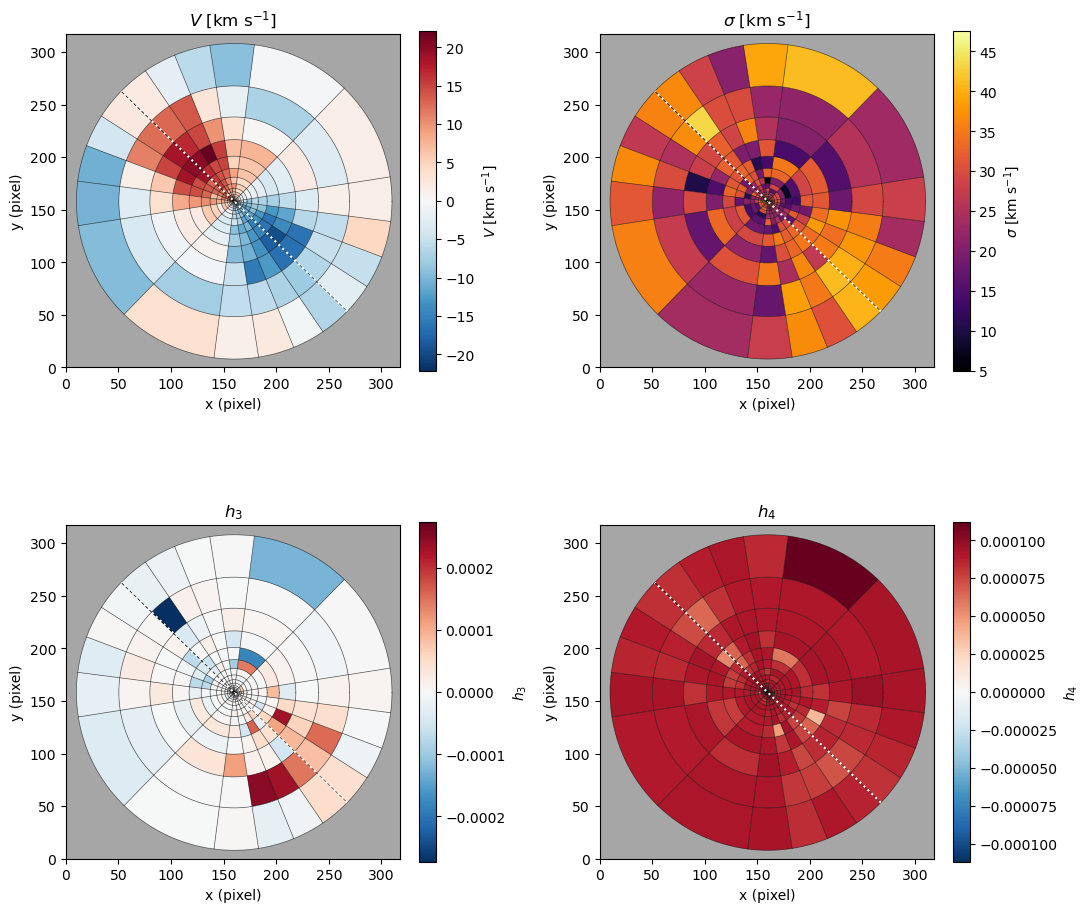

In [10]:
V = np.array([bin_data[b]["moments"]["vherm"] for b in bin_ids])
V -= np.nanmedian(V)  # remove the systemic velocity for plotting
SIGMA = np.array([bin_data[b]["moments"]["sherm"] for b in bin_ids])
H3 = np.array([bin_data[b]["moments"]["h3"] for b in bin_ids])
H3 -= np.nanmedian(H3)
H4 = np.array([bin_data[b]["moments"]["h4"] for b in bin_ids])

moment_names = ["V", "sigma", "h3", "h4"]
moment_labels = [r"$V$ [km s$^{-1}$]", r"$\sigma$ [km s$^{-1}$]", r"$h_3$", r"$h_4$"]
moment_vals = [V, SIGMA, H3, H4]

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, name, label, vals in zip(axes.ravel(), moment_names, moment_labels, moment_vals):
    cmap = "inferno" if name == "sigma" else "RdBu_r"
    plot_bin_map(ax, bin_table, bins, dict(zip(bin_ids, vals)), center_pix=bins.center,
                 pa_deg=PA_DEG, pixel_scale=pixel_scale, background=white_light,
                 cmap=cmap, colorbar_label=label)
    ax.set_xlim(0, nx); ax.set_ylim(0, ny)
    ax.set_title(label)
    ax.set_xlabel("x (pixel)"); ax.set_ylabel("y (pixel)")
plt.tight_layout(); plt.show()

## 7. Radial kinematic profiles -- V, sigma, h3, h4 along the major axis

The complementary view to the 2D maps above, and the one that actually
reads like a rotation curve: every bin's moment plotted against its own
*signed* distance along the kinematic major axis (positive on the receding
side, negative on the approaching side), restricted to a wedge of bins
close to that axis so the plotted points aren't smeared out across the
minor-axis direction where the LOSVD is dominated by dispersion, not
rotation. This is the same construction this project's own head-to-head
pPXF comparison uses for its own axis-profile plot.

Because `assign_spaxels_to_bins` was called with `pa_deg=PA_DEG`, every
bin's own `theta_mid` is *already* measured relative to the major axis (its
own `theta=0`) -- so the signed distance along the axis and the
perpendicular distance away from it fall out directly as
`r_mid*cos(theta_mid)` and `r_mid*sin(theta_mid)`, no extra rotation
needed.

53 of 275 bins selected within 11.5 deg of the major axis


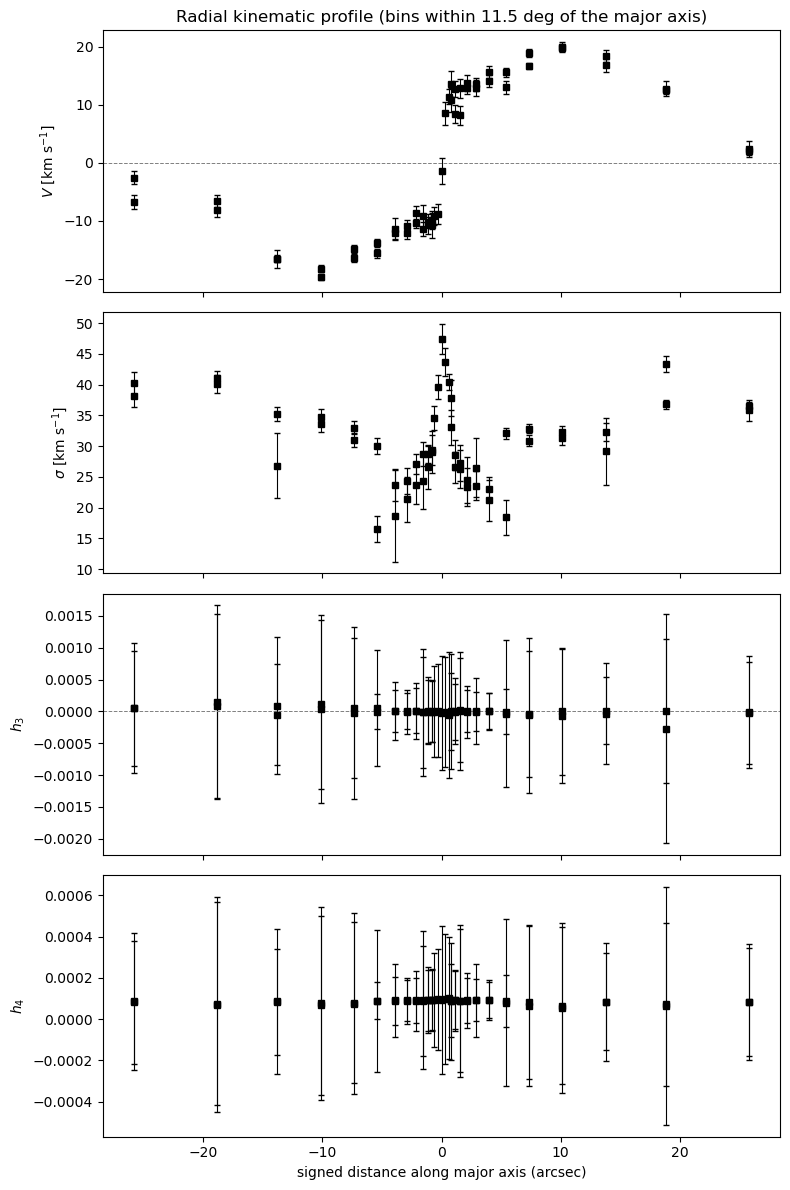

median h3_std=0.0006 vs. population's own h3 spread=0.0000 (14.2x)
median h4_std=0.0002 vs. population's own h4 spread=0.0000 (28.6x)
Each bin's own reported uncertainty dwarfing the whole galaxy's own h3/h4 spread means h3/h4 are not meaningfully constrained per bin here -- consistent with this target's low sigma (~20-50 km/s) suppressing h3 recovery by construction (README.md's own Known Limitations) and Laplace's own coverage being weakest at low sigma (this notebook's Section 7 intro). The small, well-behaved-looking point estimates above are a symptom of that suppression, not evidence this target genuinely has near-zero h3/h4 -- treat them as consistent with zero, not as a detection, anywhere this ratio is large.


In [11]:
AXIS_HALF_WIDTH_DEG = 11.5  # angular wedge half-width around the major axis

r_signed = np.full(n_bins, 0.0)
d_perp = np.full(n_bins, 0.0)
is_center = np.zeros(n_bins, dtype=bool)
for i, bid in enumerate(bin_ids):
    bd = bin_data[bid]
    if bd["theta_mid"] is None:
        is_center[i] = True
        continue
    r_signed[i] = bd["r_mid"] * np.cos(bd["theta_mid"])
    d_perp[i] = bd["r_mid"] * np.sin(bd["theta_mid"])

# fold across the +/- axis direction (theta_mid near 0 or near pi are both "on axis")
phi_folded = np.minimum(np.abs(d_perp / np.maximum(np.array([bin_data[b]["r_mid"] for b in bin_ids]), 1e-6)),
                         1.0)
angle_from_axis_deg = np.degrees(np.arcsin(phi_folded))
axis_mask = (angle_from_axis_deg <= AXIS_HALF_WIDTH_DEG) | is_center

print(f"{axis_mask.sum()} of {n_bins} bins selected within {AXIS_HALF_WIDTH_DEG} deg of the major axis")

fig, axes = plt.subplots(4, 1, figsize=(8, 12), sharex=True)
for ax, name, label, vals in zip(axes, moment_names, moment_labels, moment_vals):
    errs = np.array([bin_data[b].get(f"{'vherm' if name=='V' else 'sherm' if name=='sigma' else 'h3' if name=='h3' else 'h4'}_std", 0.0)
                      for b in bin_ids])
    m = axis_mask
    order = np.argsort(r_signed[m])
    ax.errorbar(r_signed[m][order], vals[m][order], yerr=errs[m][order],
                fmt="s", color="black", ms=5, capsize=2, elinewidth=0.8)
    if name == "V" or name == "h3":
        ax.axhline(0.0, color="gray", lw=0.7, ls="--")
    ax.set_ylabel(label)
axes[-1].set_xlabel('signed distance along major axis (arcsec)')
axes[0].set_title(f"Radial kinematic profile (bins within {AXIS_HALF_WIDTH_DEG} deg of the major axis)")
plt.tight_layout(); plt.show()

# h3/h4's own error bars look small in absolute terms but are not small relative to what
# they're measuring -- worth checking explicitly rather than reading the plot above at
# face value. This target's own h3/h4 point estimates barely move bin to bin (both
# regularized toward the flat, near-Gaussian shape this target's own low sigma -- see
# `02_realistic_mock_fit.ipynb`'s Section 6 -- pulls them toward), so comparing each
# bin's own reported uncertainty to that same tiny population-wide spread is the honest
# read on whether h3/h4 are actually constrained here, not just well-behaved-looking.
h3_std_all = np.array([bin_data[b]["h3_std"] for b in bin_ids])
h4_std_all = np.array([bin_data[b]["h4_std"] for b in bin_ids])
h3_spread = np.std([bin_data[b]["moments"]["h3"] for b in bin_ids])
h4_spread = np.std([bin_data[b]["moments"]["h4"] for b in bin_ids])
print(f"median h3_std={np.median(h3_std_all):.4f} vs. population's own h3 spread={h3_spread:.4f} "
      f"({np.median(h3_std_all)/h3_spread:.1f}x)")
print(f"median h4_std={np.median(h4_std_all):.4f} vs. population's own h4 spread={h4_spread:.4f} "
      f"({np.median(h4_std_all)/h4_spread:.1f}x)")
print("Each bin's own reported uncertainty dwarfing the whole galaxy's own h3/h4 spread means "
      "h3/h4 are not meaningfully constrained per bin here -- consistent with this target's low "
      "sigma (~20-50 km/s) suppressing h3 recovery by construction (README.md's own Known "
      "Limitations) and Laplace's own coverage being weakest at low sigma (this notebook's "
      "Section 7 intro). The small, well-behaved-looking point estimates above are a symptom of "
      "that suppression, not evidence this target genuinely has near-zero h3/h4 -- treat them "
      "as consistent with zero, not as a detection, anywhere this ratio is large.")

### 7b. Below the instrument's own resolution: sigma is a lam-selection lottery here

MUSE's own instrumental resolution in this fit window (8400-8800A,
the CaT triplet) works out to sigma~36-38 km/s (`kinextract.lsf.
muse_lsf_fwhm`) -- any bin whose recovered sigma sits below roughly
1.5x that (~55 km/s) is being measured at or near the instrument's own
resolution floor. **Confirmed directly on this run's own bins (not
just a synthetic mock): in that regime, recovered sigma is
non-monotonic and has no plateau across a wide fixed-`lam` ladder
(`lam_selection="aic_local"` lands on an equally arbitrary point in
the same ladder, not a systematically better one), and the reported
`sherm_std` above is 5-10x smaller than the actual lam-to-lam swing**
-- see `dev_notes/uncertainty/FINDINGS.md`'s 2026-08-11 (late) entry
for the specific bins and numbers. Treat sigma point estimates (and
their error bars) below the flagged threshold as illustrative, not a
precision measurement -- this is a genuine, currently-open information
limit (`README.md`'s own Known Limitations), not a bug this notebook
works around.

In [12]:
from kinextract.lsf import muse_lsf_fwhm, fwhm_to_sigma

_wave_mid = 8600.0  # 0.5*(WAVEFITMIN+WAVEFITMAX) -- hardcoded, not read from the fit cell's
                    # own WAVEFITMIN/WAVEFITMAX, which only exist in that cell's real-compute
                    # branch (undefined under USE_SHIPPED_RESULTS)
_inst_sigma_kms = 299792.458 * fwhm_to_sigma(muse_lsf_fwhm(_wave_mid)) / _wave_mid
_RESOLUTION_LIMITED_FACTOR = 1.5
_res_limited = np.array([bin_data[b]["moments"]["sherm"] < _RESOLUTION_LIMITED_FACTOR * _inst_sigma_kms
                          for b in bin_ids])
print(f"MUSE instrumental sigma at {_wave_mid:.0f}A: {_inst_sigma_kms:.1f} km/s")
print(f"{_res_limited.sum()}/{n_bins} bins have sherm below "
      f"{_RESOLUTION_LIMITED_FACTOR}x that ({_RESOLUTION_LIMITED_FACTOR * _inst_sigma_kms:.1f} km/s) -- "
      f"treat these as illustrative, not precision measurements (see markdown above)")

MUSE instrumental sigma at 8600A: 36.7 km/s
275/275 bins have sherm below 1.5x that (55.0 km/s) -- treat these as illustrative, not precision measurements (see markdown above)


## Conclusion

**What this notebook did.** Combined every piece this notebook sequence
built and validated separately -- a calibrated template subset, PA-aware
spatial binning, sky/emission handling, correlated-noise whitening,
per-spectrum variance inflation, and parallel Laplace uncertainty -- into
a single, real, full-galaxy analysis: moment maps and a radial kinematic
profile built directly from real MUSE data at production scale.

**Key takeaways:**

- Every earlier notebook's own validated choice shows up here as a
  concrete default: the calibrated template subset (04), the measured
  `rho` (05), Laplace as the primary uncertainty engine with bootstrap as
  a cross-check (02), per-spectrum variance inflation as the default
  defense against this target's own elevated `chi2_red`.
- Failed or poorly-constrained bins degrade to `NaN` and render as plain
  grey on the moment maps, rather than crashing the whole run or silently
  reporting a meaningless number.
- **Real-data `chi2_red` runs well above 1 on this target even after
  correlated-noise whitening and variance inflation** -- a real, only
  partially understood residual on top of everything this notebook
  applies. Treat the maps and profiles above as a demonstration of the
  full pipeline working end-to-end at real scale, not a publication-ready
  NGC 5102 measurement.
- Uncertainty here is Laplace's own raw, uncorrected estimate, with no
  regularization-bias correction applied -- coverage is a real,
  substantial improvement over bootstrap but still below its nominal
  target, especially at low sigma.
- **No continuum-cofitting in this notebook** -- a deliberate demo choice
  (`CONTINUUM_KNOTS = None` in Section 3), not a package limitation:
  `laplace_continuum_uncertainty` (and the fixed-lam-per-bin-tracking
  this needs -- see `n4751_full_galaxy_analysis.ipynb`, the companion
  real-data notebook that does need continuum-cofitting) already
  supports it. Per-bin `rho` *is* re-measured here (`measure_rho=True`
  above, Section 4) -- `MEASURED_RHO` above is a fallback only, unused
  once that kicks in.

**This is the end of the notebook sequence for MUSE/E-MILES data.**
`06_other_instruments.ipynb` covers adapting this same pipeline to a
different instrument (HST/STIS) if that's what you need next. If you're
analyzing your own MUSE target, the natural path is: `04_template_calibration.ipynb`
to condition a template subset for it, `05_noise_correlation.ipynb` to
measure its own `rho`, then this notebook with `RMAX_ARCSEC`/`PA_DEG` set
to your target's own values.